# Лабораторна робота № 1. Нейронна мережа Хебба
### Інструкції, виконувані приклади та індивідуальне завдання

**Дисципліна:** «Нейронні мережі» · **Рівень:** бакалаврський  
**Основа:** методичні вказівки «ЛБ_1_Хебб (1).pdf» (2026/2027 н. р.), розділи 2–4.

**Мета:** створити одношарову мережу Хебба для розпізнавання чотирьох літер українського імені або прізвища; навчити її, перевірити результати та **виявити випадки, коли адаптація ваг не приводить до правильного розпізнавання**.

**Завдання з методички:**
1. **3.1.** Спроєктувати мережу для **чотирьох різних літер**: обґрунтувати `12 ≤ n ≤ 30` рецепторних елементів, кількість виходів і цільові вектори.
2. **3.2.** Реалізувати алгоритм Хебба та діагностику проблем навчання.
3. **3.3.** Навчити мережу розпізнавати обрані чотири символи.
4. **3.4.** Навести приклад **нерозв'язної проблеми адаптації**.

**Запуск:** Python 3.10+ / Jupyter Notebook / JupyterLab / Google Colab; GPU не потрібен. Всі приклади виконуються без датасетів з інтернету. Виконуйте клітинки зверху вниз.

> У ноутбуці є **готовий навчальний приклад** та окремий блок **«Ваша індивідуальна робота»**. Для здачі змініть навчальні літери на чотири різні літери вашого імені або прізвища, дослідіть результати та напишіть власний висновок.

## 0. Середовище та імпорт

Використовуються `numpy` (вектори й матриці) та `matplotlib` (візуалізація). У Colab зазвичай уже встановлені; для локального середовища, за потреби, запустіть у терміналі:

```bash
pip install numpy matplotlib
```

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(linewidth=130, suppress=True)
plt.rcParams['font.family'] = 'DejaVu Sans'  # підтримка кирилиці
SEED = 42
rng = np.random.default_rng(SEED)
print('NumPy:', np.__version__)
print('Готово: обчислення виконуватимуться на CPU.')

NumPy: 2.4.2
Готово: обчислення виконуватимуться на CPU.


## 1. Теорія: нейрон і правило Хебба

Для вхідного вектора $\mathbf{x}=(x_1,\ldots,x_n)$ і вектора ваг $\mathbf{w}$ нейрон обчислює

$$ S=\sum_{i=1}^{n}x_iw_i+w_0, $$

де $w_0$ — **зміщення (bias)**. У методичці для біполярного нейрона використовується поріг **строго більше нуля**:

$$ y=\begin{cases}+1,&S>0\\ -1,&S\le 0.\end{cases} $$

Тому **при $S=0$ результат дорівнює $-1$**.

Класичне кероване оновлення Хебба з **відомою правильною міткою** $t\in\{-1,+1\}$:

$$w_i^{\text{new}}=w_i^{\text{old}}+\eta x_i t, \qquad x_0=1.$$

За методичкою беремо $\eta=1$. Під час навчання $t$ — **заданий (бажаний)** вихід, а не прогноз моделі. Візьмемо $m=4$ вихідних нейрони — по одному на літеру — та біполярні цільові вектори:

$$\mathbf t_{\mathrm{О}}=(+1,-1,-1,-1),\quad
\mathbf t_{\mathrm{Л}}=(-1,+1,-1,-1),$$
$$\mathbf t_{\mathrm{Е}}=(-1,-1,+1,-1),\quad
\mathbf t_{\mathrm{К}}=(-1,-1,-1,+1).$$

Матриця ваг мережі $W\in\mathbb{R}^{(n+1)\times m}$ містить **окремий стовпець ваг для кожного вихідного нейрона**. Усі нейрони бачать той самий вхід. Для навчальної пари $\tilde{\mathbf x}=(1,x_1,\dots,x_n)$ і $\mathbf t$:

$$\boxed{W\leftarrow W+\eta\,\tilde{\mathbf x}\,\mathbf t^{\mathsf T}}$$

**Два режими, які варто розрізняти:**
- **Однопрохідний:** оновлюємо ваги для кожного навчального прикладу (як у прикладі 1 методички).
- **Ітеративний з перевіркою помилок:** перед оновленням перевіряємо прогноз; якщо вихідний **вектор** неправильний, застосовуємо правило Хебба; повторюємо проходи (розділ 2.3 методички). На відміну від правила перцептрона, **збіжність цього варіанта не гарантована навіть для деяких роздільних задач**.

In [2]:
def bipolar_step(scores):
    """Активація методички: +1 при S > 0, інакше -1."""
    return np.where(np.asarray(scores) > 0, 1, -1).astype(int)

assert bipolar_step([-3, 0, 2]).tolist() == [-1, -1, 1]
print('S = [-3, 0, 2] → y =', bipolar_step([-3, 0, 2]))

S = [-3, 0, 2] → y = [-1 -1  1]


### 1.1. Контрольний розрахунок із прикладу 1 методички

Перевіримо наведені в PDF два 9-компонентні біполярні образи ($3\times3$). Для демонстрації це **окремий приклад нейрона**; в індивідуальному завданні потрібно $12\le n\le30$.

In [3]:
x1_pdf = np.array([1, -1, 1, 1, 1, 1, -1, -1, 1])
x2_pdf = np.array([1,  1, 1, 1,-1, 1,  1, -1, 1])
w_pdf = np.zeros(10, dtype=int)  # w0 та дев'ять інших ваг

for x, target in [(x1_pdf, +1), (x2_pdf, -1)]:
    x_aug = np.r_[1, x]
    w_pdf += x_aug * target

s1 = int(np.r_[1, x1_pdf] @ w_pdf)
s2 = int(np.r_[1, x2_pdf] @ w_pdf)
print('Фінальні ваги [w0, w1, ..., w9]:', w_pdf)
print(f'S(X1) = {s1}, y(X1) = {int(bipolar_step(s1))}')
print(f'S(X2) = {s2}, y(X2) = {int(bipolar_step(s2))}')
assert (s1, s2) == (6, -6), 'Значення мають збігатися з прикладом 1 у PDF.'

Фінальні ваги [w0, w1, ..., w9]: [ 0  0 -2  0  0  2  0 -2  0  0]
S(X1) = 6, y(X1) = 1
S(X2) = -6, y(X2) = -1


## 2. Структура мережі для чотирьох літер (завдання 3.1)

Демонстраційний набір: **О, Л, Е, К** — чотири різні літери імені «Олександр».

- Кожна літера представлена **растровим зображенням $5\times5$**, тобто $n=25$ рецепторних елементів: **$12\le25\le30$**.
- Пікселі `1` — зафарбовано, `0` — фон. Для навчання переводимо до **біполярного формату**: $x_i=+1$ для зафарбованого й $x_i=-1$ для фону.
- Використовуємо **4 вихідні нейрони** ($m=4$): один відповідає кожній літері. Позитивне значення бажане **лише на правильному нейроні**.
- Мережа має $25\cdot4=100$ ваг сигналів і **4 ваги зміщення**, тобто всього **104 параметри**.

> Форми літер тут умовні навчальні матриці. Для персонального завдання можна створити власні $4\times4$, $5\times5$ або $5\times6$ шаблони — головне, щоб число пікселів було від 12 до 30 і всі чотири символи були різними.

In [4]:
DEMO_PATTERNS = {
    'О': ('01110', '10001', '10001', '10001', '01110'),
    'Л': ('00100', '01010', '10001', '10001', '10001'),
    'Е': ('11111', '10000', '11110', '10000', '11111'),
    'К': ('10001', '10010', '11100', '10010', '10001'),
}

def patterns_to_arrays(patterns):
    """Перетворити словник символів на біполярні вектори X і цілі T."""
    if len(patterns) != 4:
        raise ValueError('Мають бути рівно чотири різні літери.')
    letters = list(patterns)
    rows_per_letter = [tuple(patterns[k]) for k in letters]
    heights = {len(rows) for rows in rows_per_letter}
    widths = {len(row) for rows in rows_per_letter for row in rows}
    if len(heights) != 1 or len(widths) != 1:
        raise ValueError('Усі літери повинні мати однаковий розмір.')
    h, w = heights.pop(), widths.pop()
    if not 12 <= h * w <= 30:
        raise ValueError(f'Кількість рецепторів n={h*w}; вимога 12 ≤ n ≤ 30.')
    for rows in rows_per_letter:
        if any(set(row) - {'0', '1'} for row in rows):
            raise ValueError('Використовуйте тільки символи 0 і 1.')
        if any(len(row) != w for row in rows):
            raise ValueError('Некоректна ширина рядків.')
    binary = np.array([[int(c) for row in rows for c in row] for rows in rows_per_letter], dtype=int)
    if np.unique(binary, axis=0).shape[0] != 4:
        raise ValueError('Чотири літерам повинні відповідати чотири різні вхідні вектори.')
    X = 2 * binary - 1
    T = -np.ones((4, 4), dtype=int)
    np.fill_diagonal(T, 1)
    return letters, X, T, (h, w)

letters, X, T, glyph_shape = patterns_to_arrays(DEMO_PATTERNS)
print('Літери:', letters)
print('X.shape =', X.shape, 'T.shape =', T.shape, 'Форма літери =', glyph_shape)
print('Цільові вектори T:\n', T)

Літери: ['О', 'Л', 'Е', 'К']
X.shape = (4, 25) T.shape = (4, 4) Форма літери = (5, 5)
Цільові вектори T:
 [[ 1 -1 -1 -1]
 [-1  1 -1 -1]
 [-1 -1  1 -1]
 [-1 -1 -1  1]]


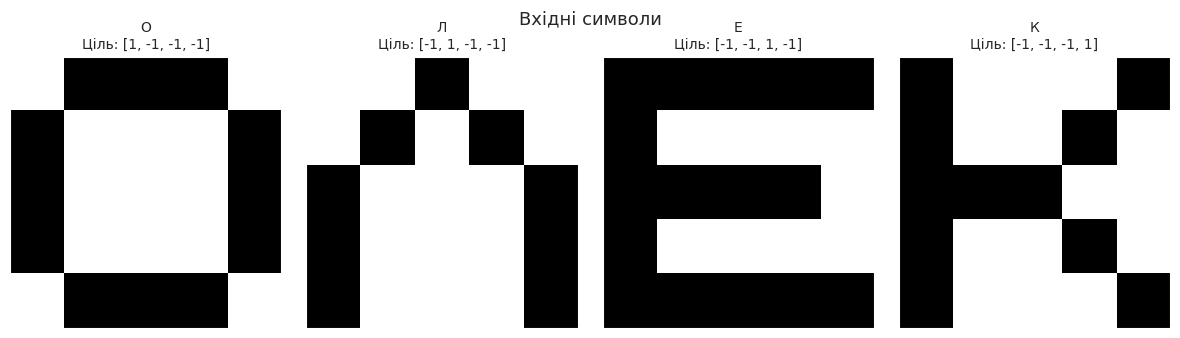

Перший вектор О:
[[-1  1  1  1 -1]
 [ 1 -1 -1 -1  1]
 [ 1 -1 -1 -1  1]
 [ 1 -1 -1 -1  1]
 [-1  1  1  1 -1]]


In [5]:
def plot_glyphs(X, labels, shape, targets=None, title='Вхідні символи'):
    n = len(X)
    fig, axs = plt.subplots(1, n, figsize=(3.0 * n, 3.4))
    axs = np.atleast_1d(axs)
    for i, (ax, x, label) in enumerate(zip(axs, X, labels)):
        ax.imshow(np.asarray(x).reshape(shape), cmap='gray_r', vmin=-1, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        subtitle = f'\nЦіль: {np.asarray(targets[i]).tolist()}' if targets is not None else ''
        ax.set_title(str(label) + subtitle, fontsize=10)
    fig.suptitle(title, fontsize=13)
    fig.tight_layout()
    plt.show()

plot_glyphs(X, letters, glyph_shape, targets=T)
print('Перший вектор О:')
print(X[0].reshape(glyph_shape))

## 3. Математика одного оновлення

Нехай до навчання $W=0$. Для першого образу **О** ціль — $(+1,-1,-1,-1)$. Після одного оновлення:

$$W_{j,:}^{(1)} = x_j\,(+1,-1,-1,-1), \quad j=0,\ldots,25.$$

Тобто для першого вихідного нейрона ваги повторюють вхід, для решти — змінюють його знак. Вага $w_{0,:}$ змінюється, адже $x_0\equiv1$.

In [6]:
def augment_bias(X):
    """Додати x0 = 1 як нульовий стовпець."""
    X = np.asarray(X, dtype=int)
    if X.ndim != 2:
        raise ValueError('Очікується двовимірна матриця: (кількість_прикладів, n).')
    return np.c_[np.ones(len(X), dtype=int), X]

x0_aug = augment_bias(X[:1])[0]
W_first = np.zeros((X.shape[1] + 1, T.shape[1]), dtype=int)
W_first += np.outer(x0_aug, T[0])
print('Перша строка W — ваги зміщення:', W_first[0])
print('Перші п’ять рядків ваг:\n', W_first[1:6])
assert np.array_equal(W_first[0], T[0])
assert W_first.shape == (26, 4)

Перша строка W — ваги зміщення: [ 1 -1 -1 -1]
Перші п’ять рядків ваг:
 [[-1  1  1  1]
 [ 1 -1 -1 -1]
 [ 1 -1 -1 -1]
 [ 1 -1 -1 -1]
 [-1  1  1  1]]


## 4. Перший підхід: один прохід правилом Хебба

Цей алгоритм **послідовно виконує оновлення для кожного** з чотирьох навчальних образів без перевірки поточного прогнозу. Йому відповідає формула

$$W = \sum_{k=1}^{4} \tilde{\mathbf x}^{(k)}\,(\mathbf t^{(k)})^{\mathsf T},$$

оскільки початкові ваги нульові та $\eta=1$.

In [7]:
def fit_hebb_one_pass(X, T, eta=1):
    Xa = augment_bias(X)
    T = np.asarray(T, dtype=int)
    if T.shape[0] != Xa.shape[0]:
        raise ValueError('Кількість векторів X і T має збігатися.')
    if not np.isin(Xa, [-1, 1]).all() or not np.isin(T, [-1, 1]).all():
        raise ValueError('Для цього прикладу потрібні біполярні X і T.')
    weights = np.zeros((Xa.shape[1], T.shape[1]), dtype=int)
    for xa, t in zip(Xa, T):
        weights += eta * np.outer(xa, t)
    return weights


def forward(X, W):
    """Повернути матриці сум S і біполярних прогнозів Y."""
    S = augment_bias(X) @ np.asarray(W)
    return S, bipolar_step(S)


def exact_accuracy(pred, targets):
    """Частка прикладів, для яких правильний ВЕСЬ вихідний вектор."""
    pred, targets = np.asarray(pred), np.asarray(targets)
    return float(np.mean(np.all(pred == targets, axis=1)))

W_one = fit_hebb_one_pass(X, T)
S_one, Y_one = forward(X, W_one)
print('W.shape =', W_one.shape)
print('Оцінки S:\n', S_one)
print('Прогнози Y:\n', Y_one)
print(f'Частка повністю правильних вихідних векторів: {exact_accuracy(Y_one, T):.0%}')

W.shape = (26, 4)
Оцінки S:
 [[ 24 -20 -16 -44]
 [-24  20 -40 -20]
 [-24 -44  16 -20]
 [-48 -20 -16  20]]
Прогнози Y:
 [[ 1 -1 -1 -1]
 [-1  1 -1 -1]
 [-1 -1  1 -1]
 [-1 -1 -1  1]]
Частка повністю правильних вихідних векторів: 100%


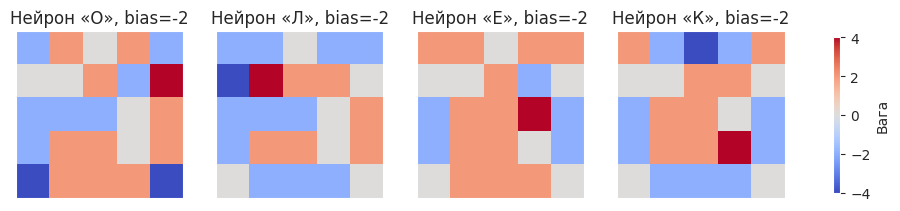

In [8]:
def plot_weight_maps(W, labels, shape):
    fig, axs = plt.subplots(1, len(labels), figsize=(3.1 * len(labels), 3.1))
    scale = max(1, np.abs(W[1:]).max())
    for j, (ax, label) in enumerate(zip(np.atleast_1d(axs), labels)):
        im = ax.imshow(W[1:, j].reshape(shape), cmap='coolwarm', vmin=-scale, vmax=scale)
        ax.set_title(f'Нейрон «{label}», bias={W[0,j]}')
        ax.set_xticks([]); ax.set_yticks([])
    fig.colorbar(im, ax=np.atleast_1d(axs).tolist(), shrink=0.65, label='Вага')
    plt.show()

plot_weight_maps(W_one, letters, glyph_shape)

### 4.1. Перевірка на кожній літері

Важливо відрізняти **`argmax(S)`** від вимоги методички. `argmax` повертає найсильніший нейрон, навіть якщо декілька виходів активні або всі мають $-1$. Для лабораторної оцінюємо **повний вектор** виходів і за потреби відмічаємо неоднозначний прогноз.

In [9]:
def inspect_predictions(X, T, W, labels):
    S, Y = forward(X, W)
    header = 'Вхід | бажаний T             | прогноз Y             | S                       | результат'
    print(header)
    print('-' * len(header))
    for name, t, y, score in zip(labels, T, Y, S):
        status = '✓ правильно' if np.array_equal(t, y) else '✗ помилка'
        print(f'{name:^5} | {str(t.tolist()):<21} | {str(y.tolist()):<21} | {str(score.tolist()):<23} | {status}')
    return exact_accuracy(Y, T)

acc_one = inspect_predictions(X, T, W_one, letters)

Вхід | бажаний T             | прогноз Y             | S                       | результат
------------------------------------------------------------------------------------------
  О   | [1, -1, -1, -1]       | [1, -1, -1, -1]       | [24, -20, -16, -44]     | ✓ правильно
  Л   | [-1, 1, -1, -1]       | [-1, 1, -1, -1]       | [-24, 20, -40, -20]     | ✓ правильно
  Е   | [-1, -1, 1, -1]       | [-1, -1, 1, -1]       | [-24, -44, 16, -20]     | ✓ правильно
  К   | [-1, -1, -1, 1]       | [-1, -1, -1, 1]       | [-48, -20, -16, 20]     | ✓ правильно


## 5. Другий підхід: ітеративне навчання з перевіркою виходів (завдання 3.2)

**Алгоритм, наближений до кроків 1–7 розділу 2.3 PDF:**

1. Початково $W=0$.
2. Для кожного навчального образу обчислюємо **весь** вихідний вектор $\mathbf y$.
3. **Якщо $\mathbf y\ne\mathbf t$**, оновлюємо **всі стовпці** матриці $W$ за $W\leftarrow W+\tilde{\mathbf x}\mathbf t^\mathsf{T}$.
4. Після проходу перевіряємо правильність **усіх** навчальних образів.
5. Зупиняємось, коли всі цілі досягнуті; інакше повторюємо.

**Щоб навчання не зависало, реалізуємо захист:**
- `max_epochs`: верхня межа кількості проходів;
- `cycle`: повторення **всієї матриці ваг після епохи** (за фіксованого порядку прикладів);
- `contradictory_targets`: однаковому входу задано різні вихідні вектори — така задача **логічно неможлива**;
- історія кількості корекцій і якості для пояснення результату.

> **Застереження:** цикл або досягнення `max_epochs` означають, що **поточний алгоритм не збігся**; це **не доводить**, що для набору не існує іншої матриці ваг. Нероздільність потрібно доводити окремо, як у XOR-прикладі нижче.

In [10]:
def contradictory_pairs(X, T):
    """Знайти пари індексів із однаковими входами і різними цілями."""
    bad = []
    for i in range(len(X)):
        for j in range(i + 1, len(X)):
            if np.array_equal(X[i], X[j]) and not np.array_equal(T[i], T[j]):
                bad.append((i, j))
    return bad


def train_hebb(X, T, max_epochs=100, eta=1):
    """Ітеративне кероване навчання Хебба; повертає W, історію та статус.

    Статуси: converged, cycle, max_epochs, contradictory_targets.
    """
    X, T = np.asarray(X, dtype=int), np.asarray(T, dtype=int)
    if X.ndim != 2 or T.ndim != 2 or X.shape[0] != T.shape[0]:
        raise ValueError('X та T мають бути двовимірними з однаковою кількістю рядків.')
    if len(X) == 0 or T.shape[1] == 0 or max_epochs < 1:
        raise ValueError('Потрібні непорожні дані та max_epochs ≥ 1.')
    if not np.isin(X, [-1, 1]).all() or not np.isin(T, [-1, 1]).all():
        raise ValueError('Ця реалізація призначена для біполярних сигналів ±1.')
    Xa = augment_bias(X)
    W = np.zeros((Xa.shape[1], T.shape[1]), dtype=int)
    history = []
    if contradictory_pairs(X, T):
        return W, history, 'contradictory_targets'

    seen = {W.tobytes()}
    for epoch in range(1, max_epochs + 1):
        updates = 0
        for xa, t in zip(Xa, T):
            y = bipolar_step(xa @ W)
            if not np.array_equal(y, t):
                W += eta * np.outer(xa, t)
                updates += 1

        _, predicted = forward(X, W)
        accuracy = exact_accuracy(predicted, T)
        history.append({'epoch': epoch, 'updates': updates, 'accuracy': accuracy,
                        'weight_norm': float(np.linalg.norm(W))})
        if accuracy == 1.0:
            return W, history, 'converged'
        key = W.tobytes()
        if key in seen:
            return W, history, 'cycle'
        seen.add(key)
    return W, history, 'max_epochs'

W_iter, history, status = train_hebb(X, T, max_epochs=100)
print('Статус:', status)
print('Історія:', history)
print('Точність:', f'{inspect_predictions(X, T, W_iter, letters):.0%}')

Статус: converged
Історія: [{'epoch': 1, 'updates': 4, 'accuracy': 1.0, 'weight_norm': 20.396078054371138}]
Вхід | бажаний T             | прогноз Y             | S                       | результат
------------------------------------------------------------------------------------------
  О   | [1, -1, -1, -1]       | [1, -1, -1, -1]       | [24, -20, -16, -44]     | ✓ правильно
  Л   | [-1, 1, -1, -1]       | [-1, 1, -1, -1]       | [-24, 20, -40, -20]     | ✓ правильно
  Е   | [-1, -1, 1, -1]       | [-1, -1, 1, -1]       | [-24, -44, 16, -20]     | ✓ правильно
  К   | [-1, -1, -1, 1]       | [-1, -1, -1, 1]       | [-48, -20, -16, 20]     | ✓ правильно
Точність: 100%


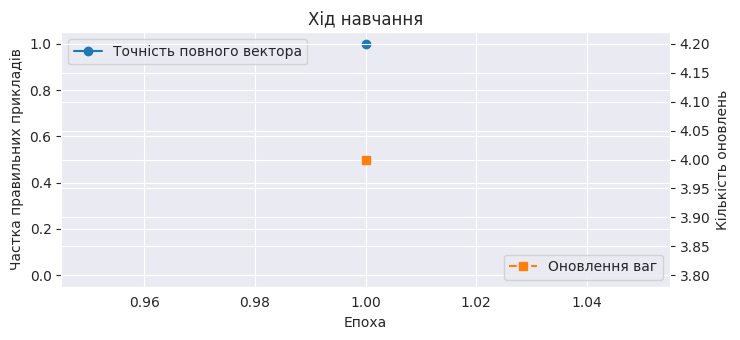

Кількість параметрів мережі: 104


In [11]:
def plot_history(history, title='Хід навчання'):
    if not history:
        print('Немає епох для побудови графіка.')
        return
    epochs = [h['epoch'] for h in history]
    accuracies = [h['accuracy'] for h in history]
    updates = [h['updates'] for h in history]
    fig, ax = plt.subplots(figsize=(7.5, 3.5))
    ax.plot(epochs, accuracies, 'o-', label='Точність повного вектора')
    ax.set_xlabel('Епоха')
    ax.set_ylabel('Частка правильних прикладів')
    ax.set_ylim(-0.05, 1.05)
    ax2 = ax.twinx()
    ax2.plot(epochs, updates, 's--', color='tab:orange', label='Оновлення ваг')
    ax2.set_ylabel('Кількість оновлень')
    ax.legend(loc='upper left')
    ax2.legend(loc='lower right')
    ax.set_title(title)
    fig.tight_layout()
    plt.show()

plot_history(history)
print('Кількість параметрів мережі:', W_iter.size)

## 6. Розпізнавання нового (можливо спотвореного) символу

Після навчання мережа отримує **вхідний вектор**, обчислює $\mathbf S$ та формує біполярні виходи. Ми приймаємо літеру лише тоді, коли **рівно один нейрон повернув +1**. Інакше результат — `невизначено`.

Для аналізу стійкості можна випадково змінювати знак окремих пікселів ($+1\leftrightarrow-1$). Це **додатковий експеримент**, а не обов'язкова умова з методички.

In [12]:
def predict_letter(x, W, labels):
    x = np.asarray(x, dtype=int).reshape(1, -1)
    S, Y = forward(x, W)
    active = np.flatnonzero(Y[0] == 1)
    result = labels[int(active[0])] if len(active) == 1 else 'невизначено'
    return result, S[0], Y[0]

for name, x in zip(letters, X):
    result, score, vector = predict_letter(x, W_iter, letters)
    print(f'{name} → {result}; S={score.tolist()}; Y={vector.tolist()}')

О → О; S=[24, -20, -16, -44]; Y=[1, -1, -1, -1]
Л → Л; S=[-24, 20, -40, -20]; Y=[-1, 1, -1, -1]
Е → Е; S=[-24, -44, 16, -20]; Y=[-1, -1, 1, -1]
К → К; S=[-48, -20, -16, 20]; Y=[-1, -1, -1, 1]


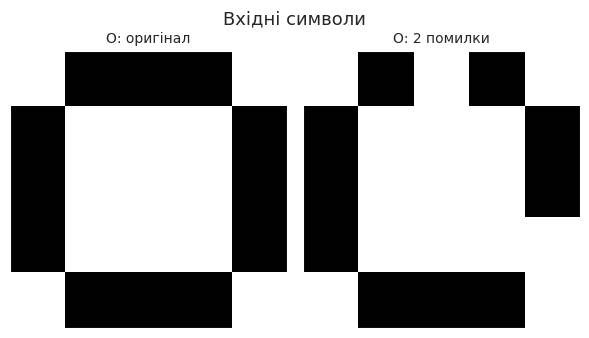

Прогноз спотвореної літери: О


In [13]:
def flip_pixels(x, n_flips, rng):
    """Поміняти знак у n_flips різних випадково вибраних пікселів."""
    x = np.asarray(x, dtype=int).copy()
    if not 0 <= n_flips <= len(x):
        raise ValueError('Кількість спотворених пікселів має бути від 0 до n.')
    idx = rng.choice(len(x), size=n_flips, replace=False)
    x[idx] *= -1
    return x

example_noisy = flip_pixels(X[0], n_flips=2, rng=np.random.default_rng(SEED))
plot_glyphs(np.vstack([X[0], example_noisy]), ['О: оригінал', 'О: 2 помилки'], glyph_shape)
print('Прогноз спотвореної літери:', predict_letter(example_noisy, W_iter, letters)[0])

Кількість змінених пікселів → частка правильних розпізнавань:
0 → 100.0%
1 → 100.0%
2 → 100.0%
3 → 98.5%
4 → 93.2%
5 → 81.0%


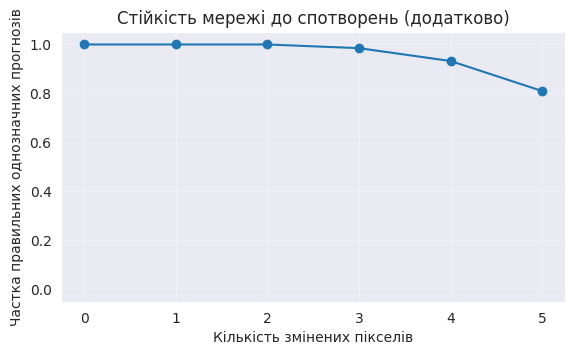

In [14]:
def noise_experiment(X, labels, W, flips=(0, 1, 2, 3, 4, 5), trials=100, seed=42):
    """Частка правильних однозначних розпізнавань для випадкових спотворень."""
    random_gen = np.random.default_rng(seed)
    results = {}
    for k in flips:
        ok = 0
        for x, label in zip(X, labels):
            for _ in range(trials):
                altered = flip_pixels(x, k, random_gen)
                pred, _, _ = predict_letter(altered, W, labels)
                ok += int(pred == label)
        results[k] = ok / (len(X) * trials)
    return results

noise_results = noise_experiment(X, letters, W_iter)
print('Кількість змінених пікселів → частка правильних розпізнавань:')
for k, acc in noise_results.items():
    print(f'{k} → {acc:.1%}')
plt.figure(figsize=(6.5, 3.5))
plt.plot(list(noise_results), list(noise_results.values()), 'o-')
plt.ylim(-0.05, 1.05)
plt.xlabel('Кількість змінених пікселів')
plt.ylabel('Частка правильних однозначних прогнозів')
plt.title('Стійкість мережі до спотворень (додатково)')
plt.grid(alpha=0.3)
plt.show()

## 7. Проблеми адаптації: неможливий приклад (завдання 3.4)

Навіть якщо реалізація правильна, **не всі набори вхідних сигналів і бажаних виходів реалізуються одним лінійним пороговим нейроном**.

### 7.1. Суперечливі вимоги для однакового входу

Якщо одному й тому самому вхідному вектору призначено **дві різні правильні відповіді**, жодна детермінована мережа не зможе задовольнити обидві. Такий випадок перевіряємо **перед початком** ітеративного навчання.

In [15]:
X_conflict = np.vstack([X[0], X[0]])
T_conflict = np.array([[1, -1], [-1, 1]])
print('Конфліктні пари індексів:', contradictory_pairs(X_conflict, T_conflict))
W_conflict, conflict_history, conflict_status = train_hebb(X_conflict, T_conflict)
print('Статус навчання:', conflict_status)
assert conflict_status == 'contradictory_targets'

Конфліктні пари індексів: [(0, 1)]
Статус навчання: contradictory_targets


### 7.2. **XOR**: різні входи, але лінійно нероздільні цілі

Цей приклад сильніший за дублікати: всі входи **різні**, однак двома класами їх неможливо правильно поділити **однією прямою / гіперплощиною**.

Візьмемо **4 символи розміром $5\times5$**. У них змінюються лише два пікселі: $a,b\in\{-1,+1\}$; решта 23 пікселі постійні. Нехай нейрон **A** повинен мати вихід $+1$, коли $a\neq b$, і $-1$ — коли $a=b$; нейрон **B** має протилежну ціль.

| $a$ | $b$ | $t_A$ | $t_B$ |
|---:|---:|---:|---:|
| $-1$ | $-1$ | $-1$ | $+1$ |
| $-1$ | $+1$ | $+1$ | $-1$ |
| $+1$ | $-1$ | $+1$ | $-1$ |
| $+1$ | $+1$ | $-1$ | $+1$ |

Це **окремий контрприклад для двох вихідних нейронів**. Для доведення нерозв'язності достатньо показати, що нейрон A не може навчитися потрібної функції.

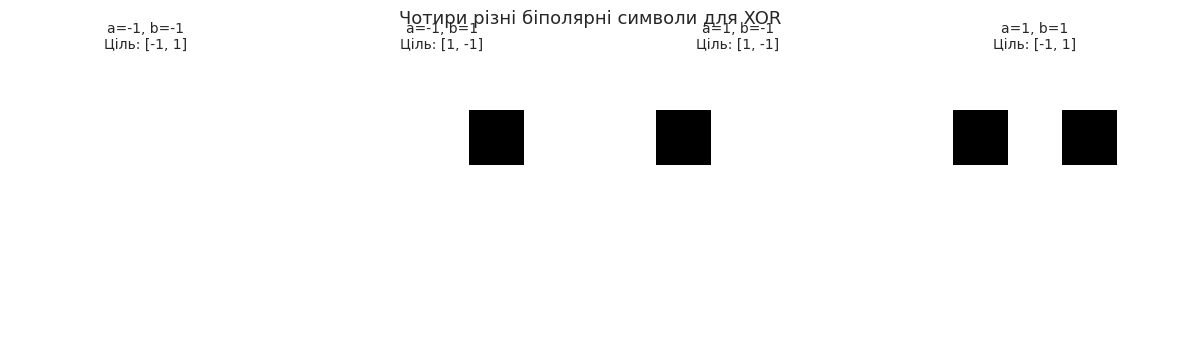

Конфлікти однакових вхідних векторів: []
Статус навчання: cycle
Повна точність: 0.0
Перші епохи: [{'epoch': 1, 'updates': 4, 'accuracy': 0.0, 'weight_norm': 0.0}]


In [16]:
X_xor = []
T_xor = []
AB = [(-1,-1), (-1, 1), (1,-1), (1, 1)]
for a, b in AB:
    x = -np.ones(25, dtype=int)
    x[6] = a          # піксель у позиції (1,1) 5x5
    x[8] = b          # піксель у позиції (1,3) 5x5
    X_xor.append(x)
    t_a = 1 if a != b else -1
    T_xor.append([t_a, -t_a])
X_xor = np.array(X_xor)
T_xor = np.array(T_xor)

plot_glyphs(X_xor, [f'a={a}, b={b}' for a,b in AB], (5, 5), T_xor,
            title='Чотири різні біполярні символи для XOR')
print('Конфлікти однакових вхідних векторів:', contradictory_pairs(X_xor, T_xor))
W_xor, xor_history, xor_status = train_hebb(X_xor, T_xor, max_epochs=30)
print('Статус навчання:', xor_status)
print('Повна точність:', exact_accuracy(forward(X_xor, W_xor)[1], T_xor))
print('Перші епохи:', xor_history[:5])
assert xor_status != 'converged'

### 7.3. Чому XOR не розв'язується лінійним нейроном? (коротке доведення)

Оскільки 23 входи постійні, їхній внесок разом зі зміщенням можна об'єднати в число $c$. Тоді сумарний вхід нейрона **A**:

$$S(a,b)=w_a a+w_b b+c.$$

Щоб для $(-1,+1)$ та $(+1,-1)$ одержати **$+1$**, потрібно:

$$-w_a+w_b+c>0,\qquad w_a-w_b+c>0.$$

Додаємо нерівності: $2c>0$, тобто $c>0$.

Щоб для $(-1,-1)$ та $(+1,+1)$ одержати **$-1$**, потрібно:

$$-w_a-w_b+c\le0,\qquad w_a+w_b+c\le0.$$

Додаємо: $2c\le0$, тобто $c\le0$. **Суперечність!** Отже, потрібної матриці ваг не існує. Ітеративне правило Хебба закономірно не може досягти 100% на цих даних.

**Висновок з 3.4:** приклад із суперечливими мітками є логічно неможливим; приклад XOR — **лінійно нероздільним**. Виявлений у коді цикл лише сигналізує про незбіжність заданого алгоритму; математичне доведення вище обґрунтовує нерозв'язність саме XOR.

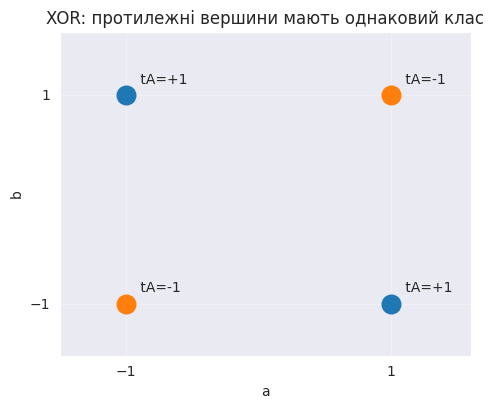

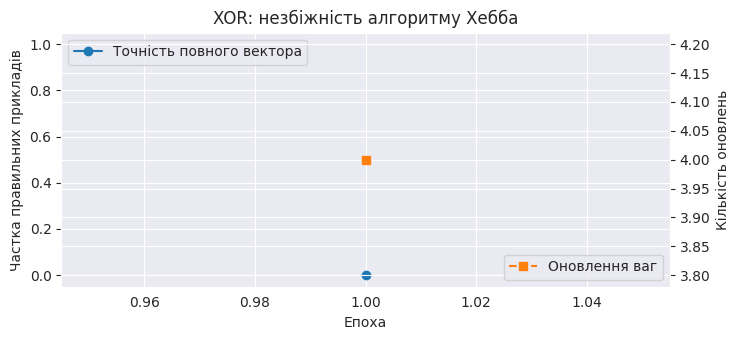

In [17]:
fig, ax = plt.subplots(figsize=(5.3, 4.2))
for (a, b), t in zip(AB, T_xor):
    color = 'tab:blue' if t[0] == 1 else 'tab:orange'
    ax.scatter(a, b, c=color, s=180)
    ax.annotate(f' tA={t[0]:+d}', (a, b), xytext=(7, 8), textcoords='offset points')
ax.set_xlim(-1.5, 1.6); ax.set_ylim(-1.5, 1.6)
ax.set_xticks([-1, 1]); ax.set_yticks([-1, 1])
ax.set_xlabel('a'); ax.set_ylabel('b')
ax.set_title('XOR: протилежні вершини мають однаковий клас')
ax.grid(alpha=0.3)
plt.show()
plot_history(xor_history, 'XOR: незбіжність алгоритму Хебба')

## 8. Автоматичні перевірки реалізації

Наведені нижче тести охоплюють **поріг $S=0$**, правильність матричного оновлення, розміри ваг, виконання на демонстраційних літерах, а також виявлення явно нерозв'язних наборів. Якщо тести не проходять після змін, перевірте реалізацію перед написанням звіту.

In [18]:
def run_basic_checks():
    assert int(bipolar_step(0)) == -1
    assert np.array_equal(bipolar_step([-2, 0, 0.1]), [-1, -1, 1])
    assert augment_bias(np.array([[1, -1]])).tolist() == [[1, 1, -1]]
    assert np.array_equal(W_first, np.outer(np.r_[1, X[0]], T[0]))
    assert W_one.shape == (26, 4)
    assert exact_accuracy(forward(X, W_one)[1], T) == 1.0
    assert status == 'converged'
    assert exact_accuracy(forward(X, W_iter)[1], T) == 1.0
    assert conflict_status == 'contradictory_targets'
    assert xor_status in {'cycle', 'max_epochs'}
    assert exact_accuracy(forward(X_xor, W_xor)[1], T_xor) < 1.0
    print('✅ Усі базові тести пройдено.')

run_basic_checks()

✅ Усі базові тести пройдено.


## 9. **Ваша індивідуальна робота** — замініть демонстраційні символи

**Завдання для студента:**

1. Виберіть **4 різні літери власного імені чи прізвища**. Намалюйте кожну у форматі `0/1` з однаковою роздільністю, щоб $12\le n\le30$. Вкажіть, чому обрано саме таку роздільність.
2. У словнику `STUDENT_PATTERNS` **замініть приклад** власними літерами; переконайтеся, що вони різні.
3. Побудуйте матриці $X$ та $T$, назвіть кількість рецепторних і вихідних нейронів та число ваг зі зміщеннями.
4. Навчіть мережу **обома способами**: одноразово та ітеративно; порівняйте ваги, вектори виходів і кількість епох.
5. Перевірте виходи на всіх чотирьох літерах; за бажанням — спотворені варіанти.
6. Продемонструйте **необхідність діагностики** проблем адаптації за прикладом XOR або власним нерозв'язним набором; поясніть **чому** його неможливо класифікувати.

**УВАГА:** наступна комірка стартує з демонстраційними літерами лише для перевірки працездатності ноутбука. Перед здачею **обов'язково змініть цей словник** на власні символи.

Літери: ['О', 'С', 'Т', 'П']
Рецепторних нейронів: n=20; вихідних нейронів: m=4; параметрів: (n+1)·m=84
Вектори цілей:
 [[ 1 -1 -1 -1]
 [-1  1 -1 -1]
 [-1 -1  1 -1]
 [-1 -1 -1  1]]


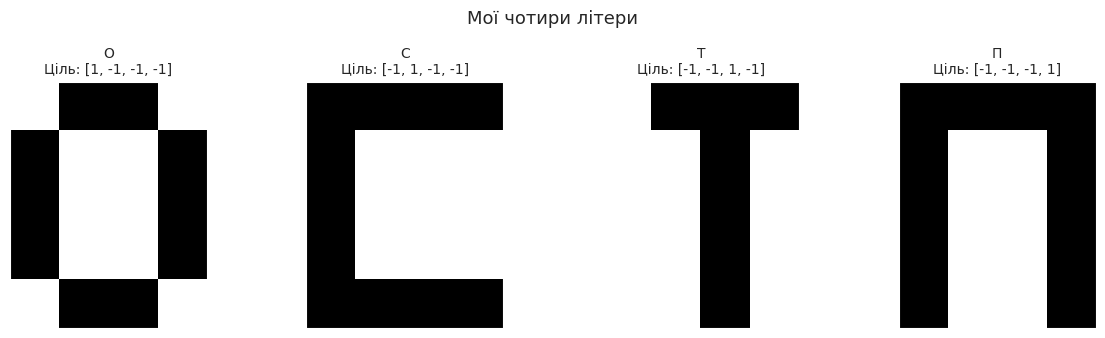

In [24]:
# TODO 1: замініть ці чотири літери на чотири РІЗНІ літери вашого імені або прізвища.
# Кожне зображення має складатися з однакового числа рядків та стовпців.
# '1' = піксель літери; '0' = тло. Можна почати з 5x5 (n=25).
STUDENT_PATTERNS = {
    'О': ('0110', '1001', '1001', '1001', '0110'),
    'С': ('1111', '1000', '1000', '1000', '1111'),
    'Т': ('0111', '0010', '0010', '0010', '0010'),
    'П': ('1111', '1001', '1001', '1001', '1001')
}

my_letters, X_my, T_my, my_shape = patterns_to_arrays(STUDENT_PATTERNS)
my_n = X_my.shape[1]
my_m = T_my.shape[1]
print('Літери:', my_letters)
print(f'Рецепторних нейронів: n={my_n}; вихідних нейронів: m={my_m}; параметрів: (n+1)·m={(my_n+1)*my_m}')
print('Вектори цілей:\n', T_my)
plot_glyphs(X_my, my_letters, my_shape, T_my, title='Мої чотири літери')

Однопрохідне навчання:
Вхід | бажаний T             | прогноз Y             | S                       | результат
------------------------------------------------------------------------------------------
  О   | [1, -1, -1, -1]       | [1, -1, -1, -1]       | [6, -22, -38, -18]      | ✓ правильно
  С   | [-1, 1, -1, -1]       | [-1, 1, -1, -1]       | [-26, 2, -38, -18]      | ✓ правильно
  Т   | [-1, -1, 1, -1]       | [-1, -1, 1, -1]       | [-18, -14, 26, -26]     | ✓ правильно
  П   | [-1, -1, -1, 1]       | [-1, -1, -1, 1]       | [-18, -14, -46, 6]      | ✓ правильно
Ітеративне навчання: converged
Вхід | бажаний T             | прогноз Y             | S                       | результат
------------------------------------------------------------------------------------------
  О   | [1, -1, -1, -1]       | [1, -1, -1, -1]       | [6, -22, -38, -18]      | ✓ правильно
  С   | [-1, 1, -1, -1]       | [-1, 1, -1, -1]       | [-26, 2, -38, -18]      | ✓ правильно
  Т   | [-1, -1, 1

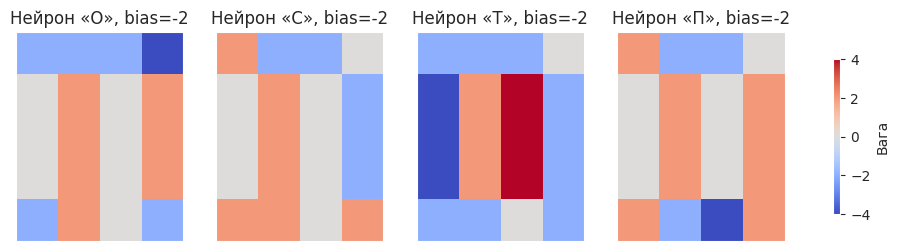

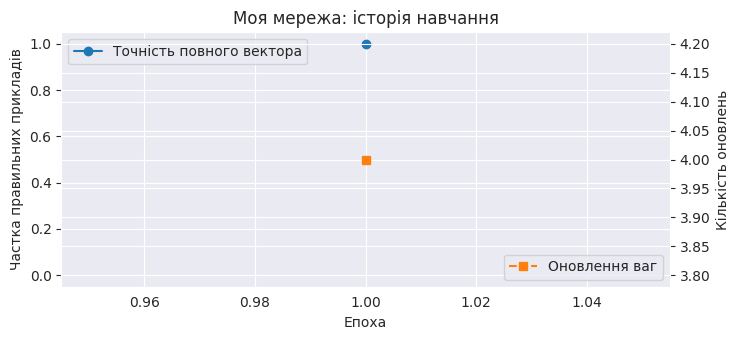

In [20]:
# TODO 2: навчіть мережу й опишіть отримані результати у звіті.
W_my_once = fit_hebb_one_pass(X_my, T_my)
W_my, my_history, my_status = train_hebb(X_my, T_my, max_epochs=100)

print('Однопрохідне навчання:')
acc_my_one = inspect_predictions(X_my, T_my, W_my_once, my_letters)
print('Ітеративне навчання:', my_status)
acc_my = inspect_predictions(X_my, T_my, W_my, my_letters)
print(f'Порівняння: один прохід {acc_my_one:.0%}; ітеративно {acc_my:.0%}; епох {len(my_history)}')
plot_weight_maps(W_my, my_letters, my_shape)
plot_history(my_history, 'Моя мережа: історія навчання')

In [23]:
# TODO 3 (додатково): дослідіть стійкість власної мережі до спотворень.
my_noise = noise_experiment(X_my, my_letters, W_my, flips=(0, 1, 2, 3), trials=50, seed=20)
for k, value in my_noise.items():
    print(f'{k} змінених пікселів → правильних прогнозів: {value:.1%}')

0 змінених пікселів → правильних прогнозів: 100.0%
1 змінених пікселів → правильних прогнозів: 89.0%
2 змінених пікселів → правильних прогнозів: 81.0%
3 змінених пікселів → правильних прогнозів: 79.5%


## 10. Запитання для самоперевірки

1. Чим $w_0$ відрізняється від ваг $w_1,\ldots,w_n$? Чому можна записати $x_0=1$?
2. Чому у цій лабораторній зручно використовувати біполярні сигнали $(-1,+1)$?
3. Що означають розміри матриць $X\in\{-1,+1\}^{4\times25}$, $T\in\{-1,+1\}^{4\times4}$ та $W\in\mathbb Z^{26\times4}$?
4. Чому для чотирьох літер обрано **чотири** вихідні нейрони, хоча один нейрон може представити лише два стани?
5. Який вихід має нейрон за $S=0$ у методичці?
6. Чому $\operatorname{argmax}(S)$ може маскувати помилку повного вихідного вектора?
7. Чим відрізняється однопрохідне навчання Хебба від ітеративного навчання з перевіркою поточного прогнозу?
8. Чому `max_epochs` і `cycle` необхідні, але самі по собі не доводять математичну нероздільність задачі?
9. Чому XOR неможливо реалізувати одним лінійним пороговим нейроном?
10. Як зміниться навчання, якщо поміняти порядок образів, кількість рецепторів або спосіб представлення символів?

## 11. Структура звіту (за розділом 4 методички)

**4.1. Тема:** «Нейронна мережа Хебба»; мета лабораторної.

**4.2. Індивідуальне завдання:** чотири літери вашого імені/прізвища; таблиця пікселів / зображення; вибір $n$ та $m$, пояснення цільових біполярних векторів.

**4.3. Результати:** програмний код і короткий опис алгоритму; матриці $X$, $T$ і навчені $W$; таблиця $\mathbf S$, $\mathbf y$ для кожної літери; число епох і статус зупинки; хоча б один приклад проблем адаптації та її обґрунтування; за бажанням — експеримент із зашумленням.

**4.4. Обґрунтований висновок:** чи навчилась мережа; чому саме така архітектура та представлення ознак; переваги та обмеження алгоритму Хебба; чим відрізняються збіжність конкретної процедури та принципова лінійна нероздільність.

**Рекомендована перевірка перед здачею:**
- [ ] Усі 4 літери **різні** і взяті з вашого імені або прізвища.
- [ ] $12\le n\le30$; $m=4$; цільові вектори відповідають 4 класам.
- [ ] Реалізовані $x_0=1$, оновлення $W$, перевірка правильних виходів.
- [ ] Передбачені захист від нескінченного навчання та виявлення суперечливих міток.
- [ ] Показано приклад **нерозв'язного** набору з поясненням.
- [ ] Є аргументований висновок (не лише перелік дій).

**Відтворюваність:** зафіксовано генератор випадкових чисел (`SEED`), але шумові експерименти — випадкові оцінки, а не гарантовані властивості мережі.